In [22]:
import pandas as pd 
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

In [ ]:
cols = ['price', 'year', 'manufacturer', 'model', 'condition', 'cylinders',
        'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'type', 'state']
data = pd.read_csv('C:/VsCodeProjects/Used_Cars/vehicles.csv', usecols=cols)

print(data.describe().round().astype(int))
print("Original data: ", data.shape)

            price    year  odometer
count      426880  425675    422480
mean        75199    2011     98043
std      12182282       9    213882
min             0    1900         0
25%          5900    2008     37704
50%         13950    2013     85548
75%         26486    2017    133542
max    3736928711    2022  10000000
Original data:  (426880, 13)


In [3]:
# Cleaning
data = data[data['price'].between(1000, 100000)]
data = data[data['year'].between(1990, 2022)]
data = data[data['odometer'].between(100, 400000)]

data = data.drop_duplicates(subset=['price', 'year', 'manufacturer', 'model', 'odometer'])

for col in ['manufacturer', 'title_status', 'type', 'condition']:
    data[col] = data[col].fillna('unknown')

data['cylinders'] = pd.to_numeric(data['cylinders'].str.split().str[0], errors='coerce')
data['cylinders'] = data['cylinders'].fillna(data['cylinders'].median())

data = data.dropna(subset=['fuel', 'transmission'])

print("After cleaning:", data.shape)
print(data[['price', 'year', 'odometer']].describe())

After cleaning: (202938, 13)
               price           year       odometer
count  202938.000000  202938.000000  202938.000000
mean    15773.893081    2010.880875  108499.721107
std     13273.945035       6.086795   63030.678527
min      1000.000000    1990.000000     100.000000
25%      6298.000000    2007.000000   60000.000000
50%     11900.000000    2012.000000  105000.000000
75%     20999.000000    2016.000000  150000.000000
max    100000.000000    2022.000000  400000.000000


In [ ]:
features = ['year', 'odometer', 'cylinders', 'fuel', 'transmission', 'manufacturer', 'title_status', 'type']
X = pd.get_dummies(data[features], columns=['fuel', 'transmission', 'manufacturer', 'title_status', 'type'])
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Linear Regression

lr_model = LinearRegression()
lr_model.fit(X_train,y_train)
lr_mae = mean_absolute_error(y_test, lr_model.predict(X_test))
print('Linear Regression MAE: ', lr_mae)

# Naive MAE

naive_pred = np.full(len(y_test), y_train.median())
naive_mae = mean_absolute_error(y_test, naive_pred)
print('Naive MAE: ', naive_mae)

Linear Regression MAE:  5462.445523973084
Naive MAE:  9390.500886961663
Random Forest Regressor:  3728.753599654432
RF train MAE: 1385.2289612729958
1 1413.2108006300612 3761.7072825274713
3 2490.807424340767 3718.418633721254
5 2898.8287379654835 3745.7792921267514
10 3320.763894160084 3811.252053443193


In [35]:
# Random Forest Regressor 

rf_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
rf_mae = mean_absolute_error(y_test, rf_model.predict(X_test))
print('Random Forest Regressor: ', rf_mae)

imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(10))

Random Forest Regressor:  3701.939095330452
year                    0.475160
odometer                0.147173
fuel_diesel             0.116157
cylinders               0.098865
type_pickup             0.014862
type_truck              0.012087
type_SUV                0.007901
type_sedan              0.007402
manufacturer_porsche    0.006537
manufacturer_ford       0.006520
dtype: float64


In [26]:
# Hist Gradient Boosting Regressor

hgb = HistGradientBoostingRegressor(loss='absolute_error', max_iter=300, random_state=42)
hgb.fit(X_train, y_train)
hgb_mae = mean_absolute_error(y_test, hgb.predict(X_test))
print("Gradient boosting MAE:", hgb_mae)

Gradient boosting MAE: 3604.552406651204


In [27]:
results = pd.DataFrame({
    'Model': ['Naive (median)', 'Linear regression', 'Random forest', 'Gradient boosting'],
    'MAE ($)': [naive_mae, lr_mae, rf_mae, hgb_mae]
})
results['MAE ($)'] = results['MAE ($)'].round(0).astype(int)
print(results.sort_values('MAE ($)'))

               Model  MAE ($)
3  Gradient boosting     3605
2      Random forest     3702
1  Linear regression     5462
0     Naive (median)     9391


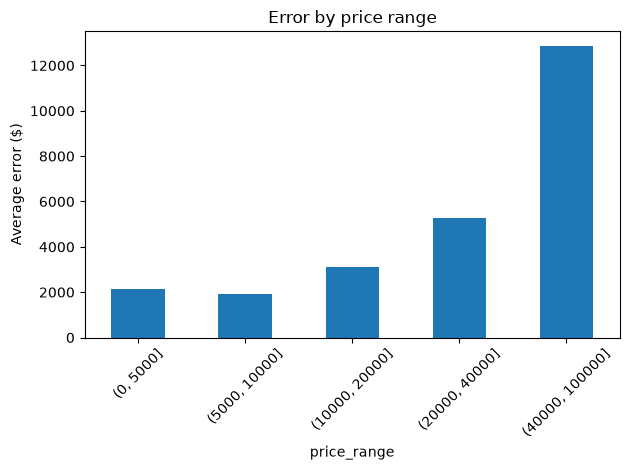

In [31]:
import matplotlib.pyplot as plt

best_pred = hgb.predict(X_test)

errors = pd.DataFrame({'actual': y_test, 'abs_error': (y_test - best_pred).abs()})
errors['price_range'] = pd.cut(errors['actual'], bins=[0, 5000, 10000, 20000, 40000, 100000])
errors.groupby('price_range', observed=True)['abs_error'].mean().plot(kind='bar')
plt.ylabel('Average error ($)')
plt.title('Error by price range')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



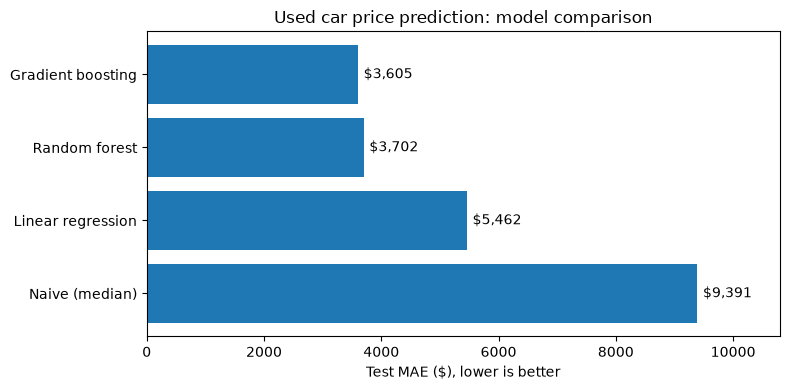

In [33]:
plot_df = results.sort_values('MAE ($)', ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(plot_df['Model'], plot_df['MAE ($)'])
ax.bar_label(bars, labels=[f"${v:,}" for v in plot_df['MAE ($)']], padding=4)
ax.set_xlabel('Test MAE ($), lower is better')
ax.set_title('Used car price prediction: model comparison')
ax.set_xlim(0, plot_df['MAE ($)'].max() * 1.15)
plt.tight_layout()